# Data Preparation Walkthrough
### Making ONS mental health data ready for analysis

## The task

**Scenario:** A data scientist wants to explore **depression and everyday life** in Great Britain. I provide the **data engineering support**: turning ONS's published workbook into one clean, trustworthy, analysis-ready table.

**Why I built it:** I designed this scenario as a portfolio project, giving myself realistic requirements to build against. My aims:
- Prepare real, messy public data for analysis
- Build a **reusable pipeline** that runs on future releases
- Follow **development best practice**: TDD, version control, documentation
- Structure the code so it's **easy to maintain**

### Research questions

| # | Question | Tables |
|---|---|---|
| 1 | How do **trust, belonging, support and loneliness** differ with depressive symptoms? | 1, 5, 6, 7, 11 |
| 2 | Which **worries** are most linked to depressive symptoms? | 1, 2 |
| 3 | Do **self-care and help-seeking** differ with depressive symptoms? | 1, 3 |
| 4 | How do **depression, trust and hope** vary by age? | 1, 4, 9 |
| 5 | Do adults with depressive symptoms **prioritise different things** for their community? | 1, 8 |

All five compare group-level estimates using 95% confidence intervals. They show associations, not causes.

### What the data scientist needs

| They ask for… | So I… |
|---|---|
| *"Everything in one place"* | Combine all 11 tables, tracing each row to its source |
| *"Ready to analyse"* | Convert estimates to numbers and standardise column names |
| *"Numbers I can trust"* | Flag suppressed values and run quality checks before handover |
| *"Works on the next release"* | Avoid hard-coding, keep configuration in one place, and unit-test every function |

## The dataset

- **Source:** ONS Opinions and Lifestyle Survey, Great Britain, 2–27 April 2025
- **Format:** one Excel workbook with **11 tables**
- **Content:** group-level estimates (% or mean score) with 95% confidence limits, broken down by age, sex, depression status and more
- **Challenges:** notes above each table, column names that aren't code-friendly, and suppression markers (`[c]`, `[low]`, `[w]`)

## Project structure

```
ons-data/
├── data/
│   ├── raw/            ← original workbook, never edited
│   └── processed/      ← analysis-ready output
├── src/ons_mental_health/
│   ├── load.py         ← read tables from Excel
│   ├── transform.py    ← wrangle and combine
│   ├── clean.py        ← handle suppression markers
│   ├── validate.py     ← reusable quality checks
│   └── pipeline.py     ← runs every step
├── tests/              ← pytest unit tests
└── notebooks/          ← exploratory data analysis
```

## Approach

**Agile delivery and version control**
- I delivered in **small working increments**: load → combine → clean → validate
- I tracked work in **GitHub Issues**, with one **branch per feature**
- I merged through **pull requests linked to issues**, so `main` always works
- I updated the README as the project grew

**Reusable functions**
- Each function has one job, e.g. `union_tables` or `handle_suppression_markers`
- Configuration (paths, markers, columns) lives in `pipeline.py`, not in the functions
- One command runs everything: `python -m ons_mental_health.pipeline`
- This notebook **imports** the pipeline's functions, with no separate cleaning code

**Testing**
- I wrote functions **test-first** with **pytest**: 35 tests, all passing
- The tests cover edge cases: empty input, missing values, unknown markers and range limits
- Functions never modify their input, and **fail loudly** on unexpected data

**Architecture**
- Runs **on-premise** today, on local compute and local files
- **Portable by design**: an installable package with no machine-specific paths
- Moving to cloud storage and scheduled runs would mostly mean changing configuration, not code

### Scope and limitations

- I use **published** tables. I expect ONS analysts would more likely work with **record-level data** in a secure environment
- Published tables are still widely used, by local authorities, the NHS and researchers, and messy data from other organisations is common
- The engineering (reliable loading, cleaning, validation and repeatability) transfers directly

In [1]:
import pandas as pd
from pathlib import Path
from openpyxl import load_workbook

DATA_DIR = Path("../data")
RAW_DATA_PATH = DATA_DIR / "raw" / "mentalhealth2to27april2025.xlsx"
CLEANED_DATA_PATH = DATA_DIR / "processed" / "mentalhealth2to27april2025_cleaned.csv"

In [2]:
df_raw = pd.read_excel(io=RAW_DATA_PATH, sheet_name="Table_1"  )

## Data preparation: issues and how they were solved

### Initial issues

| Issue | Considerations | Solution | Where in the code | Skill evidenced |
|---|---|---|---|---|
| **Notes above the data in every sheet** | • Start row varies by sheet<br>• Hard-coding would be fragile<br>• Must work on future releases | • **openpyxl** reads ONS's named Excel tables<br>• The workbook says where the data is | • `pipeline.py` opens the workbook<br>• `load.py` → one DataFrame per table | • **Reusable cleansing & checks:** works on future releases unchanged<br>• **Data manipulation tools:** chose openpyxl over pandas' basic Excel reader |
| **Data spread across 11 tables** | • Research question needs 4+ tables: trust, belonging, support, loneliness<br>• Separate tables mean manual comparison<br>• Must stay traceable to the ONS source | • **Union** into one analysis-ready table<br>• Compare all measures by depression status in one filter<br>• `source_table` column for provenance | • `union_tables` in `transform.py`<br>• `pd.concat` stacks the tables | • **Engineering support:** structure designed around the data scientist's question<br>• **Data manipulation tools:** pandas union |
| **Column names aren't code-friendly** | • Spaces, capitals, brackets<br>• Not every table has the same columns<br>• Spelling may change in future releases | • **Normalise** to `lower_snake_case` before combining<br>• Error if two names collide | • `normalise_column_names` → `normalise_name`<br>• Tested with pytest | • **Reusable cleansing & checks:** guards against future spelling drift<br>• Unit-tested and fails loudly |

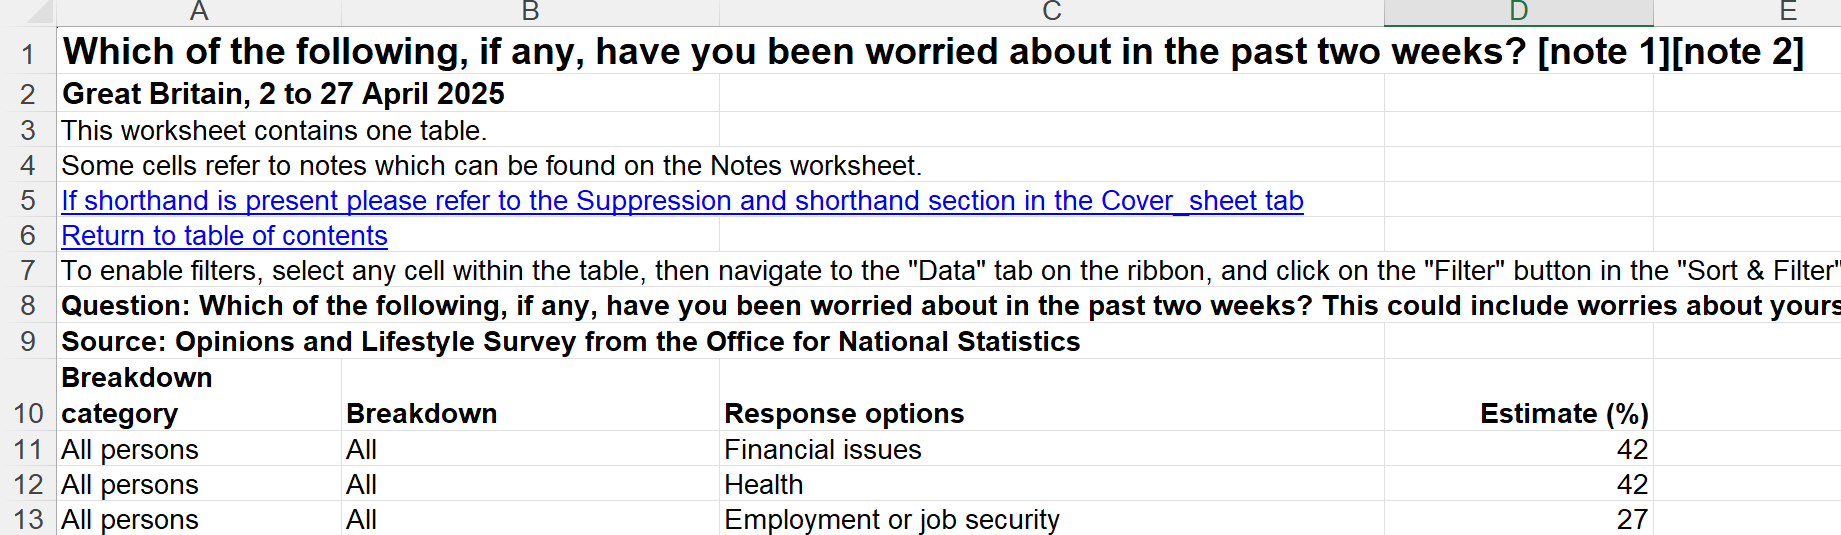

#### Demo: helper function from load.py that retrieves a collection of tables

In [3]:
from ons_mental_health.load import get_dfs_from_sheets
workbook = load_workbook(RAW_DATA_PATH, data_only=True)
df_dict = get_dfs_from_sheets(workbook)
print(f"Loaded {len(df_dict)} tables: {list(df_dict)}")
df_dict["Table_1"].head()

Loaded 11 tables: ['Table_1', 'Table_2', 'Table_3', 'Table_4', 'Table_5', 'Table_6', 'Table_7', 'Table_8', 'Table_9', 'Table_10', 'Table_11']


,Breakdown category,Breakdown,Response options,Estimate (%),LCL,UCL,Sample size,Weighted count
0,All persons,All,No or mild symptoms,82,80,83,4600,53839692
1,All persons,All,Moderate to severe symptoms,18,17,20,4600,53839692
2,Age bands,16 to 29,No or mild symptoms,74,68,80,260,9933335
3,Age bands,16 to 29,Moderate to severe symptoms,26,20,32,260,9933335
4,Age bands,30 to 49,No or mild symptoms,80,76,83,660,18076707


### Tables unioned

✅ Notes rows dropped: only the real data loaded

✅ 11 tables combined into one 572-row table

✅ Column names normalised to `lower_snake_case`

✅ `source_table` column traces every row back to ONS



In [5]:
from ons_mental_health.transform import union_tables

df_concatenated = union_tables(df_dict)
df_concatenated.sample(frac=0.1, random_state=19).head()

,source_table,breakdown_category,breakdown,response_options,estimate_(%),lcl,ucl,sample_size,weighted_count,estimate_(mean_score_out_of_10),notes
60,Table_2,Age bands,70 and over,Employment or job security,3,2,3,1970,9202432,NaN,NaN
361,Table_7,Depression indicator,Moderate to severe symptoms,Disagree,10,7,14,590,9946444,NaN,NaN
133,Table_3,Age bands,16 to 29,Took part in community or volunteering activities,8,4,12,260,9933335,NaN,NaN
108,Table_2,Depression indicator,Moderate to severe symptoms,Social or political issues,52,47,58,590,9942359,NaN,NaN
462,Table_8,Depression indicator,Moderate to severe symptoms,Trust between people,57,52,63,590,9941041,NaN,NaN


### Handling the suppression markers
| Issue | Considerations | Solution | Where in the code | Skill evidenced |
|---|---|---|---|---|
| **Suppression markers in numeric columns** (`[c]`, `[low]`, `[w]`) | • Text blocks calculations<br>• Blanket use of NaN loses information <br>• All 8 affected rows required for research question<br>• Possible unknown marker | • Markers → missing values (NaN) <br>• `is_suppressed` flag keeps the information<br>• Unknown values **raise an error** | • `handle_suppression_markers` in `clean.py`<br>• Marker list set in `pipeline.py`<br>• `pd.to_numeric` converts the rest | • **Reusable cleansing & checks:** marker list is configurable, not hard coded. Fails loudly on unknown values<br>• **Engineering support:** flag tells the data scientist which estimates to treat with caution |

In [ ]:
df_concatenated.iloc[567: 570]

,source_table,breakdown_category,breakdown,response_options,estimate_(%),lcl,ucl,sample_size,weighted_count,estimate_(mean_score_out_of_10),notes
567,Table_11,Depression indicator,Moderate to severe symptoms,Never,4,2,6,590,9946444,NaN,NaN
568,Table_11,Depression indicator,Moderate to severe symptoms,Don't know,[w],[w],[w],590,9946444,NaN,NaN
569,Table_11,Depression indicator,Moderate to severe symptoms,Prefer not to say,2,0,4,590,9946444,NaN,NaN


In [ ]:
df_concatenated.dtypes

source_table                           str
breakdown_category                     str
breakdown                              str
response_options                       str
estimate_(%)                           str
lcl                                    str
ucl                                    str
sample_size                          int64
weighted_count                       int64
estimate_(mean_score_out_of_10)    float64
notes                                  str
dtype: object

### Suppression markers handled

✅ Markers replaced with NaN values

✅ is_suppressed column retains information

In [ ]:
df_clean = pd.read_csv(CLEANED_DATA_PATH)
df_clean.iloc[567: 570]

,source_table,breakdown_category,breakdown,response_options,estimate_(%),lcl,ucl,sample_size,weighted_count,estimate_(mean_score_out_of_10),notes,is_suppressed
567,Table_11,Depression indicator,Moderate to severe symptoms,Never,4.0,2.0,6.0,590,9946444,NaN,NaN,False
568,Table_11,Depression indicator,Moderate to severe symptoms,Don't know,NaN,NaN,NaN,590,9946444,NaN,NaN,True
569,Table_11,Depression indicator,Moderate to severe symptoms,Prefer not to say,2.0,0.0,4.0,590,9946444,NaN,NaN,False


### Validating the cleaned data

| Issue | Considerations | Solution | Where in the code | Skill evidenced |
|---|---|---|---|---|
| **Same label spelled differently between tables** | • `"Strongly agree or Agree"` vs `"Strongly Agree or Agree"`<br>• Grouping would split one category in two<br>• Easy to miss by eye across 572 rows | • Check flags labels that match once case and spaces are ignored<br>• Reports every variant side by side | • `find_inconsistent_labels` in `validate.py`<br>• `groupby` + `transform("nunique")` | • **Reusable cleansing & checks:** works on any text column, any release<br>• **Engineering support:** catches errors before they reach the data scientist |
| **Values could be implausible** | • Percentages must be 0-100, scores 0-10<br>• A bad value would quietly distort results<br>• Suppressed values are missing and mustn't be flagged | • Range check returns any out-of-range rows<br>• Missing values ignored | • `find_out_of_range_values` in `validate.py`<br>• pandas `between` | • **Reusable cleansing & checks:** one function, any column and range<br>• Unit-tested, including the edge cases |

In [ ]:
from ons_mental_health.validate import find_inconsistent_labels, find_out_of_range_values

# Labels: show each spelling variant and which table it comes from
inconsistent = find_inconsistent_labels(df_clean, "response_options")
print(f"{len(inconsistent)} rows with inconsistent labels")
display(inconsistent.groupby(["response_options", "source_table"]).size())

# Ranges: one line per column
print(f"Out-of-range %: {len(find_out_of_range_values(df_clean, 'estimate_(%)', 0, 100))} rows")
print(f"Out-of-range scores: {len(find_out_of_range_values(df_clean, 'estimate_(mean_score_out_of_10)', 0, 10))} rows")

18 rows with inconsistent labels


response_options         source_table
Strongly Agree or Agree  Table_7         9
Strongly agree or Agree  Table_6         9
dtype: int64

Out-of-range %: 0 rows
Out-of-range scores: 0 rows


In [ ]:
df_clean.sample(n=5, random_state=3)

,source_table,breakdown_category,breakdown,response_options,estimate_(%),lcl,ucl,sample_size,weighted_count,estimate_(mean_score_out_of_10),notes,is_suppressed
386,Table_8,Age bands,16 to 29,Caring for future generations,34.0,27.0,40.0,260,9933335,NaN,NaN,False
451,Table_8,Depression indicator,No or mild symptoms,Helping or giving support to the community,36.0,34.0,39.0,4010,43803465,NaN,NaN,False
528,Table_11,Age bands,70 and over,Some of the time,13.0,11.0,14.0,1970,9206516,NaN,NaN,False
280,Table_6,Sex,Male,Disagree or Strongly disagree,16.0,13.0,19.0,2290,26169523,NaN,[note 4],False
323,Table_7,Age bands,50 to 69,Strongly agree,44.0,40.0,47.0,1710,16671595,NaN,NaN,False
